In [1]:
import sys
!{sys.executable} -m pip install -U numpy pandas matplotlib seaborn scikit-learn jupyterlab


[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [4]:
df=pd.read_csv("amazon_sales_2025_INR for research paper.csv")
print(df.info())
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          15000 non-null  str    
 1   Date              15000 non-null  str    
 2   Customer_ID       15000 non-null  str    
 3   Product_Category  15000 non-null  str    
 4   Product_Name      15000 non-null  str    
 5   Quantity          15000 non-null  int64  
 6   Unit_Price_INR    15000 non-null  float64
 7   Total_Sales_INR   15000 non-null  float64
 8   Payment_Method    15000 non-null  str    
 9   Delivery_Status   15000 non-null  str    
 10  Review_Rating     15000 non-null  int64  
 11  Review_Text       15000 non-null  str    
 12  State             15000 non-null  str    
 13  Country           15000 non-null  str    
dtypes: float64(2), int64(2), str(10)
memory usage: 1.6 MB
None
           Quantity  Unit_Price_INR  Total_Sales_INR  Review_Rating
count  15000.00000

In [5]:
data=pd.DataFrame(df)

In [6]:
print(data)


        Order_ID        Date Customer_ID Product_Category      Product_Name  \
0      ORD100000  25-01-2025    CUST2796   Home & Kitchen      Cookware Set   
1      ORD100001  28-08-2025    CUST9669           Beauty        Hair Dryer   
2      ORD100002  27-02-2025    CUST5808      Electronics            Tablet   
3      ORD100003  24-02-2025    CUST5889      Electronics        Headphones   
4      ORD100004  15-06-2025    CUST9005         Clothing             Saree   
...          ...         ...         ...              ...               ...   
14995  ORD114995  12-04-2025    CUST2822           Beauty          Lipstick   
14996  ORD114996  29-08-2025    CUST6143           Beauty           Shampoo   
14997  ORD114997  27-01-2025    CUST6747            Books  Science Textbook   
14998  ORD114998  21-06-2025    CUST2748           Beauty        Hair Dryer   
14999  ORD114999  07-08-2025    CUST9174   Home & Kitchen     Mixer Grinder   

       Quantity  Unit_Price_INR  Total_Sales_INR   

In [7]:
df.isnull().sum()

Order_ID            0
Date                0
Customer_ID         0
Product_Category    0
Product_Name        0
Quantity            0
Unit_Price_INR      0
Total_Sales_INR     0
Payment_Method      0
Delivery_Status     0
Review_Rating       0
Review_Text         0
State               0
Country             0
dtype: int64


MODEL COMPARISON TABLE
                      Model  MeanAbsoluteError  RootMeanSquareError  R2 Score
3  Random Forest Regression           0.000725             0.001074  0.999999
2            ANN Regression           0.030890             0.039159  0.998461
1           KNN Regression            0.246624             0.325217  0.893821
0         Linear Regression           0.262405             0.352706  0.875114

Linear Regression Train R2: 0.8827434657351397
Linear Regression Test R2 : 0.8751139327232637

KNN Best Model Train R2: 0.9141320635181974
KNN Best Model Test R2 : 0.8938214967510015

ANN Train R2: 0.9989306684810482
ANN Test R2 : 0.9984606317756729

Random Forest Train R2: 0.9999998346141181

Random Forest Test R2: 0.9999988423306464


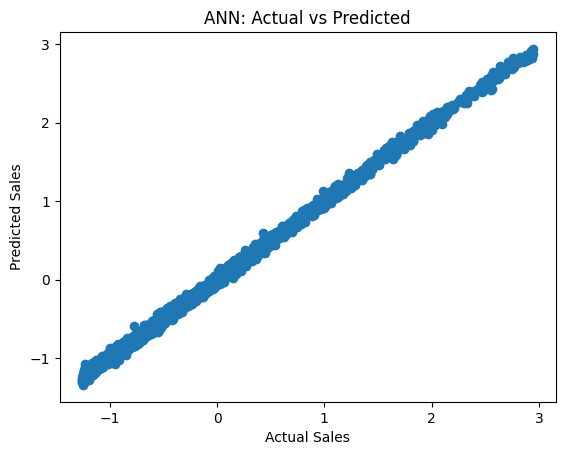

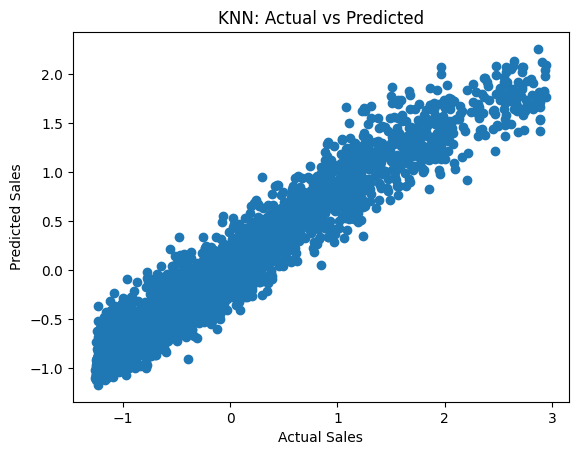

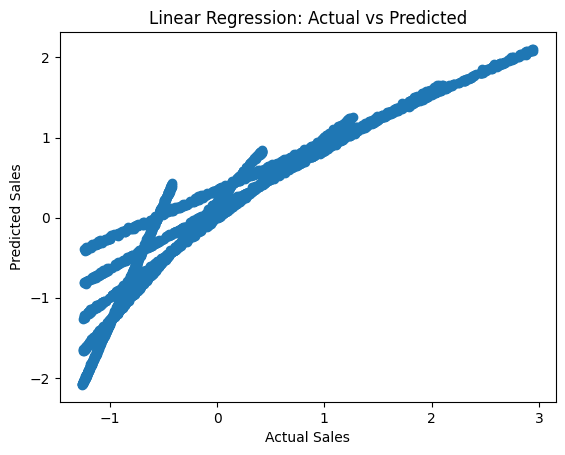

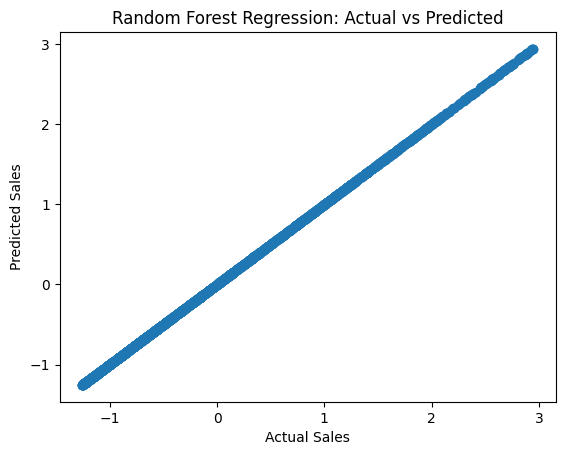

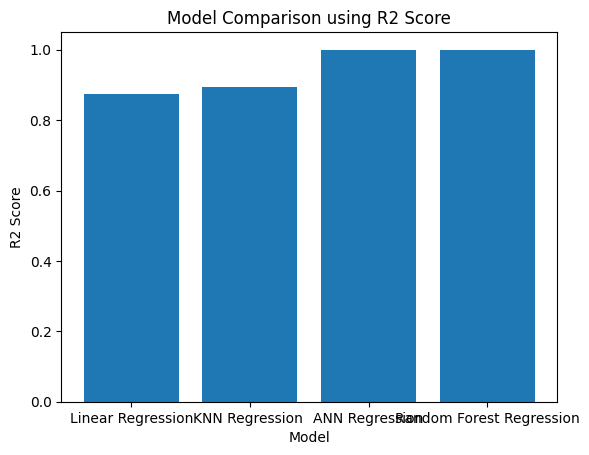

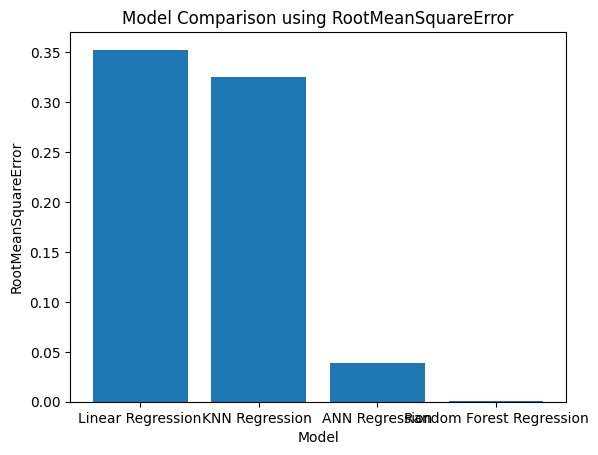

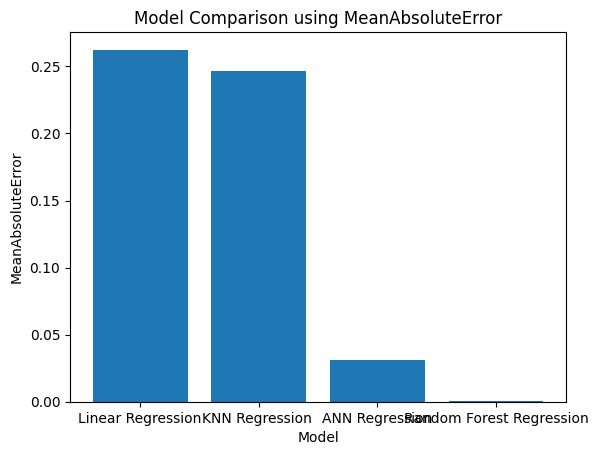

In [12]:
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.preprocessing import LabelEncoder,StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
import numpy as np
from sklearn.ensemble import RandomForestRegressor

for col in df.select_dtypes(include='object').columns:
    df[col] = LabelEncoder().fit_transform(df[col])
    
x = df.drop(columns=["Total_Sales_INR"])
y = df["Total_Sales_INR"]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42)

scaler_x = StandardScaler()
scaler_y = StandardScaler()
x_train = scaler_x.fit_transform(x_train)
x_test = scaler_x.transform(x_test)    
y_train = scaler_y.fit_transform(y_train.values.reshape(-1,1)).ravel()
y_test = scaler_y.transform(y_test.values.reshape(-1,1)).ravel()

#LinearRegression
mod1 = LinearRegression()
mod1.fit(x_train, y_train)
pred_mod1 = mod1.predict(x_test)

#GridSearchCV for KNN Regression
pipe=Pipeline([
    ("model", KNeighborsRegressor())
])

mod2=GridSearchCV(estimator=pipe,
                param_grid={'model__n_neighbors':[1,2,3,4,5,6,7,8,9,10]},
                cv=5,
               n_jobs=-1)

mod2.fit(x_train,y_train)
best_model = mod2.best_estimator_
pred_mod2 = best_model.predict(x_test)



#ANN 
mod3=MLPRegressor(
     hidden_layer_sizes=(128,64,32),
    activation='relu',
    solver='adam',
    max_iter=300,
    random_state=42
)

mod3.fit(x_train, y_train)

pred_mod3 = mod3.predict(x_test)

#RandomForest
mod4 = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    random_state=42
)

mod4.fit(x_train, y_train)
pred_mod4 = mod4.predict(x_test)


#Results
def regression_metrics(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    return [model_name, mae, rmse, r2]

results = []
results.append(regression_metrics(y_test, pred_mod1, "Linear Regression"))
results.append(regression_metrics(y_test, pred_mod2, "KNN Regression "))
results.append(regression_metrics(y_test, pred_mod3, "ANN Regression"))
results.append(regression_metrics(y_test, pred_mod4, "Random Forest Regression"))

results_df = pd.DataFrame(results, columns=["Model", "MeanAbsoluteError", "RootMeanSquareError", "R2 Score"])

print("\nMODEL COMPARISON TABLE")
print(results_df.sort_values(by="R2 Score", ascending=False))



print("\nLinear Regression Train R2:", mod1.score(x_train, y_train))
print("Linear Regression Test R2 :", mod1.score(x_test, y_test))

print("\nKNN Best Model Train R2:", best_model.score(x_train, y_train))
print("KNN Best Model Test R2 :", best_model.score(x_test, y_test))

print("\nANN Train R2:", mod3.score(x_train, y_train))
print("ANN Test R2 :", mod3.score(x_test, y_test))

print("\nRandom Forest Train R2:", mod4.score(x_train, y_train))
print("\nRandom Forest Test R2:", mod4.score(x_test, y_test))

#ANN Graph
plt.figure()
plt.scatter(y_test, pred_mod3)
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("ANN: Actual vs Predicted")
plt.show()

#KNN Graph
plt.figure()
plt.scatter(y_test, pred_mod2)
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("KNN: Actual vs Predicted")
plt.show()

#LinearRegression Graph
plt.figure()
plt.scatter(y_test, pred_mod1)
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Linear Regression: Actual vs Predicted")
plt.show()

#RandomForestRegression
plt.figure()
plt.scatter(y_test, pred_mod4)
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Random Forest Regression: Actual vs Predicted")
plt.show()

#R^2 Graph
plt.figure()
plt.bar(results_df["Model"], results_df["R2 Score"])
plt.xlabel("Model")
plt.ylabel("R2 Score")
plt.title("Model Comparison using R2 Score")
plt.show()

#RMSE Graph
plt.figure()
plt.bar(results_df["Model"], results_df["RootMeanSquareError"])
plt.xlabel("Model")
plt.ylabel("RootMeanSquareError")
plt.title("Model Comparison using RootMeanSquareError")
plt.show()

#MAE Graph
plt.figure()
plt.bar(results_df["Model"], results_df["MeanAbsoluteError"])
plt.xlabel("Model")
plt.ylabel("MeanAbsoluteError")
plt.title("Model Comparison using MeanAbsoluteError")
plt.show()

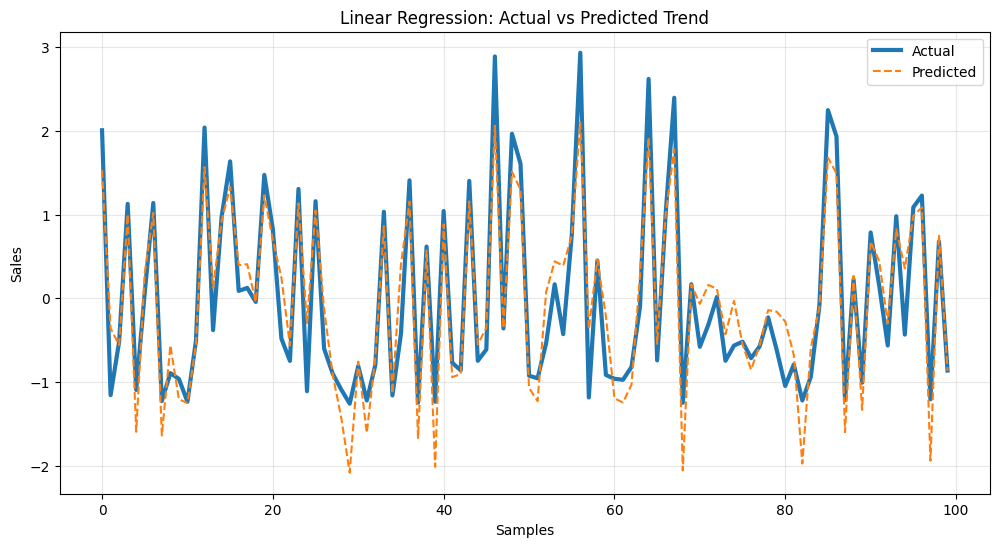

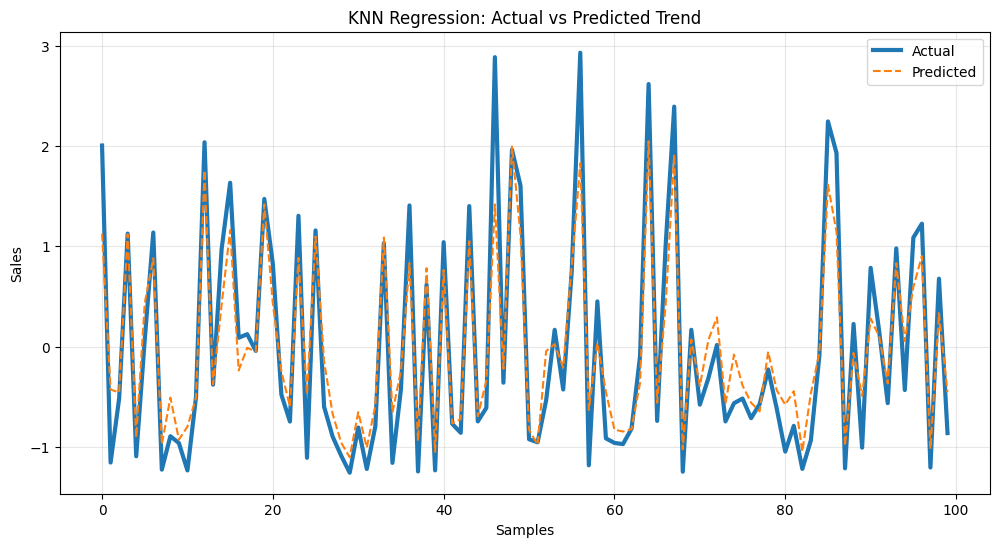

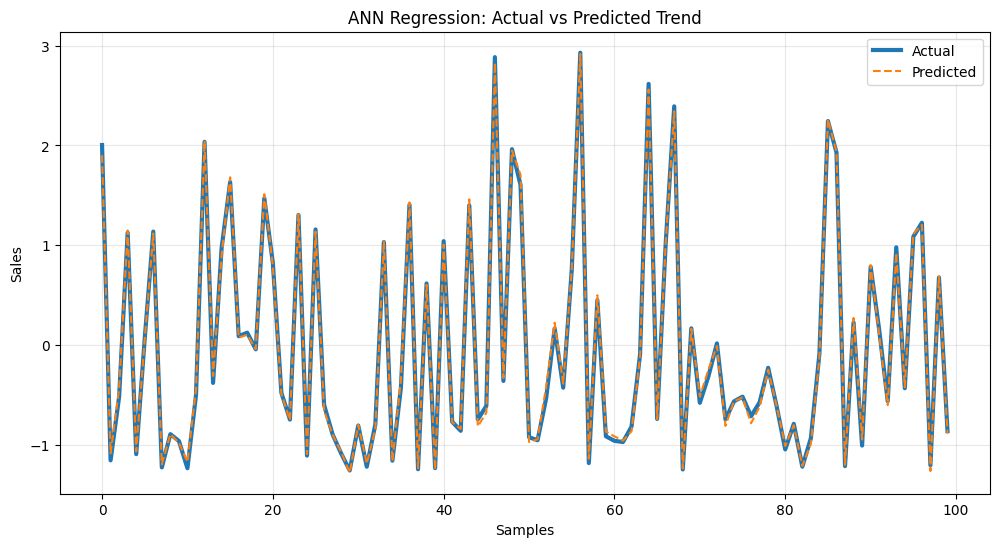

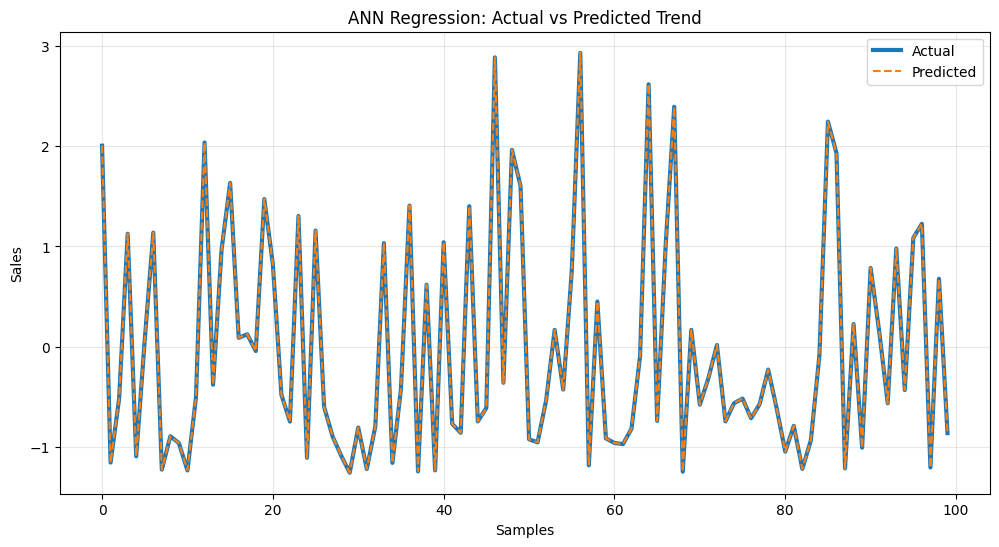

In [14]:
def plot_trend(y_true, y_pred, title):
    plt.figure(figsize=(12,6))
    plt.plot(y_true[:100], label="Actual", linewidth=3)
    plt.plot(y_pred[:100], label="Predicted", linestyle="--")
    plt.xlabel("Samples")
    plt.ylabel("Sales")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

plot_trend(y_test, pred_mod1, "Linear Regression: Actual vs Predicted Trend")
plot_trend(y_test, pred_mod2, "KNN Regression: Actual vs Predicted Trend")
plot_trend(y_test, pred_mod3, "ANN Regression: Actual vs Predicted Trend")
plot_trend(y_test, pred_mod4, "ANN Regression: Actual vs Predicted Trend")